# I - Chargement et premier profilage
Objectif : comprendre la structure du dataset avant tout nettoyage.

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [92]:
df = pd.read_csv("../data/marketing_campaign.csv", sep="\t")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [93]:
print(df.shape)
df.info()

(2240, 29)
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [94]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [95]:
df.isna().sum()[df.isna().sum() > 0]

Income    24
dtype: int64

In [96]:
display(df.describe().T)
df.nunique().sort_values()

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


Z_Revenue                 1
Z_CostContact             1
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
Complain                  2
AcceptedCmp2              2
Response                  2
Teenhome                  3
Kidhome                   3
Education                 5
Marital_Status            8
NumStorePurchases        14
NumCatalogPurchases      14
NumDealsPurchases        15
NumWebPurchases          15
NumWebVisitsMonth        16
Year_Birth               59
Recency                 100
MntFruits               158
MntSweetProducts        177
MntFishProducts         182
MntGoldProds            213
MntMeatProducts         558
Dt_Customer             663
MntWines                776
Income                 1974
ID                     2240
dtype: int64

In [97]:
print(df["Education"].value_counts())
print(df["Marital_Status"].value_counts())

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


### Conclusions
- Le dataset contient **2 240 clients** et **29 variables** : profil socio-démographique, dépenses par catégorie de produits sur 2 ans, canaux d'achat et réponses à 6 campagnes marketing.
- Le fichier est séparé par des tabulations (`sep="\t"`).
- **Problèmes de qualité identifiés :**
  - `Income` contient 24 valeurs manquantes (~1 %).
  - `ID` est un identifiant sans valeur prédictive ; `Z_CostContact` et `Z_Revenue` sont constantes.
  - `Dt_Customer` est lue comme du texte au lieu d'une date.
  - Valeurs aberrantes : années de naissance antérieures à 1900, un revenu de 666 666.
  - `Marital_Status` contient des catégories rares ou incohérentes (« YOLO », « Absurd »).
- Il n'y a **pas de variable cible** : il s'agit d'un problème non supervisé. La qualité des segments sera évaluée par des métriques internes et par leur utilité métier.

# II - Nettoyage des données
Objectif : produire un dataset propre (sans valeurs manquantes, sans aberrations, catégories simplifiées) prêt pour le feature engineering.

## 1. Suppression des colonnes inutiles
- `ID` : identifiant sans information comportementale.
- `Z_CostContact`, `Z_Revenue` : colonnes constantes (une seule valeur unique).

In [98]:
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])

## 2. Valeurs manquantes de `Income`
Environ 1 % de valeurs manquantes. Imputation par la médiane, car la moyenne est tirée vers le haut par des revenus extrêmes.

In [99]:
print("Manquants avant :", df["Income"].isna().sum())
df["Income"] = df["Income"].fillna(df["Income"].median())
print("Manquants après :", df["Income"].isna().sum())

Manquants avant : 24
Manquants après : 0


## 3. Conversion de `Dt_Customer`
On vérifie d'abord si le premier nombre peut dépasser 12 (ce serait alors le jour).

In [100]:
premier_nombre = df["Dt_Customer"].str.split("-").str[0].astype(int)
print("Max du premier nombre :", premier_nombre.max())

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
print(df["Dt_Customer"].min(), "→", df["Dt_Customer"].max())

Max du premier nombre : 31
2012-07-30 00:00:00 → 2014-06-29 00:00:00


## 4. Valeurs aberrantes
- `Year_Birth` ≤ 1900 : âges supérieurs à 110 ans, probables erreurs de saisie.
- `Income` extrême (666 666) : très éloigné de tous les autres clients.

In [103]:
print("Avant :", df.shape)
print(df.loc[df["Year_Birth"] <= 1900, "Year_Birth"].tolist())
print(df["Income"].sort_values(ascending=False).head(5).tolist())

df = df[(df["Year_Birth"] > 1900) & (df["Income"] < 600_000)]
print("Après :", df.shape)

Avant : (2236, 26)
[]
[162397.0, 160803.0, 157733.0, 157243.0, 157146.0]
Après : (2236, 26)


## 5. Simplification des catégories
- `Marital_Status` → En couple / Seul (ce qui compte pour les habitudes d'achat ; élimine aussi les catégories farfelues).
- `Education` → 3 niveaux cohérents.

In [104]:
df["Marital_Status"] = df["Marital_Status"].replace({
    "Married": "En couple", "Together": "En couple",
    "Single": "Seul", "Divorced": "Seul", "Widow": "Seul",
    "Alone": "Seul", "Absurd": "Seul", "YOLO": "Seul",
})

df["Education"] = df["Education"].replace({
    "Basic": "Premier cycle", "2n Cycle": "Premier cycle",
    "Graduation": "Licence",
    "Master": "Postgrad", "PhD": "Postgrad",
})

print(df["Marital_Status"].value_counts())
print(df["Education"].value_counts())

Marital_Status
En couple    1442
Seul          794
Name: count, dtype: int64
Education
Licence          1126
Postgrad          855
Premier cycle     255
Name: count, dtype: int64


## 6. Vérification finale et sauvegarde

In [105]:
print("Forme finale :", df.shape)
print("Valeurs manquantes :", df.isna().sum().sum())

# df.to_csv("../data/clients_nettoyes.csv", index=False)

Forme finale : (2236, 26)
Valeurs manquantes : 0


### Conclusions
- Colonnes `ID`, `Z_CostContact` et `Z_Revenue` supprimées.
- Valeurs manquantes de `Income` imputées par la **médiane**, robuste aux valeurs extrêmes (la suppression des ~1 % de lignes était aussi défendable).
- `Dt_Customer` convertie en date (format jour-mois-année).
- 4 clients aberrants retirés (3 nés en 1900 ou avant, 1 revenu de 666 666), car ils fausseraient les distances et pourraient former un cluster à eux seuls.
- `Marital_Status` regroupé en « En couple » / « Seul » et `Education` en 3 niveaux, pour éliminer les catégories rares qui ajouteraient du bruit.
- **Dataset final : 2 236 clients, 26 variables, aucune valeur manquante.**

# III - Feature engineering

In [111]:
# Date de référence : la dernière inscription du dataset (les données datent de 2014)
date_ref = df["Dt_Customer"].max()

# Âge au moment de la collecte des données
df["Age"] = date_ref.year - df["Year_Birth"]

# Ancienneté client, en mois
df["Anciennete_mois"] = (date_ref - df["Dt_Customer"]).dt.days // 30

# Dépenses totales sur 2 ans, toutes catégories
cols_depenses = ["MntWines", "MntFruits", "MntMeatProducts",
                 "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["Depenses_totales"] = df[cols_depenses].sum(axis=1)

# Nombre total d'achats, tous canaux confondus
cols_achats = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df["Achats_totaux"] = df[cols_achats].sum(axis=1)

# Composition du foyer
df["Enfants"] = df["Kidhome"] + df["Teenhome"]
df["Taille_foyer"] = df["Enfants"] + df["Marital_Status"].map({"En couple": 2, "Seul": 1})
df["Est_parent"] = (df["Enfants"] > 0).astype(int)

# Sensibilité au marketing : nombre de campagnes acceptées
cols_campagnes = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
                  "AcceptedCmp4", "AcceptedCmp5", "Response"]
df["Campagnes_acceptees"] = df[cols_campagnes].sum(axis=1)

df[["Age", "Anciennete_mois", "Depenses_totales", "Achats_totaux",
    "Enfants", "Taille_foyer", "Campagnes_acceptees"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2236.0,45.101968,11.703281,18.0,37.0,44.0,55.0,74.0
Anciennete_mois,2236.0,11.321109,6.730526,0.0,6.0,11.0,17.0,23.0
Depenses_totales,2236.0,605.986583,601.865156,5.0,69.0,396.5,1045.5,2525.0
Achats_totaux,2236.0,12.546512,7.206577,0.0,6.0,12.0,18.0,32.0
Enfants,2236.0,0.950805,0.752204,0.0,0.0,1.0,1.0,3.0
Taille_foyer,2236.0,2.595707,0.907468,1.0,2.0,3.0,3.0,5.0
Campagnes_acceptees,2236.0,0.447227,0.891113,0.0,0.0,0.0,1.0,5.0


### Conclusions
- Nouvelles variables créées : `Age`, `Anciennete_mois`, `Depenses_totales`, `Achats_totaux`, `Enfants`, `Taille_foyer`, `Est_parent`, `Campagnes_acceptees`.
- L'âge et l'ancienneté sont calculés par rapport à la date des données ([année de date_ref]) et non à aujourd'hui, pour décrire le client au moment de ses achats.
- **Choix de modélisation clé :** le clustering est fait uniquement sur les **variables comportementales** (ce que le client achète, comment, et son engagement). Les variables socio-démographiques sont réservées au profilage des segments, pour trois raisons :
  1. des segments comportementaux se traduisent directement en actions marketing ;
  2. on évite des segments dominés par le revenu ou l'âge ;
  3. constater après coup que les segments diffèrent démographiquement valide leur pertinence de façon indépendante.
- `Depenses_totales` et `Achats_totaux` sont exclues du clustering : ce sont des sommes d'autres variables, elles doubleraient le poids de cette information dans les distances. Elles serviront au profilage.
- **13 variables retenues pour le clustering** : les 6 `Mnt*`, les 4 `Num*Purchases`, `NumWebVisitsMonth`, `Recency` et `Campagnes_acceptees`.

# IV - Analyse exploratoire

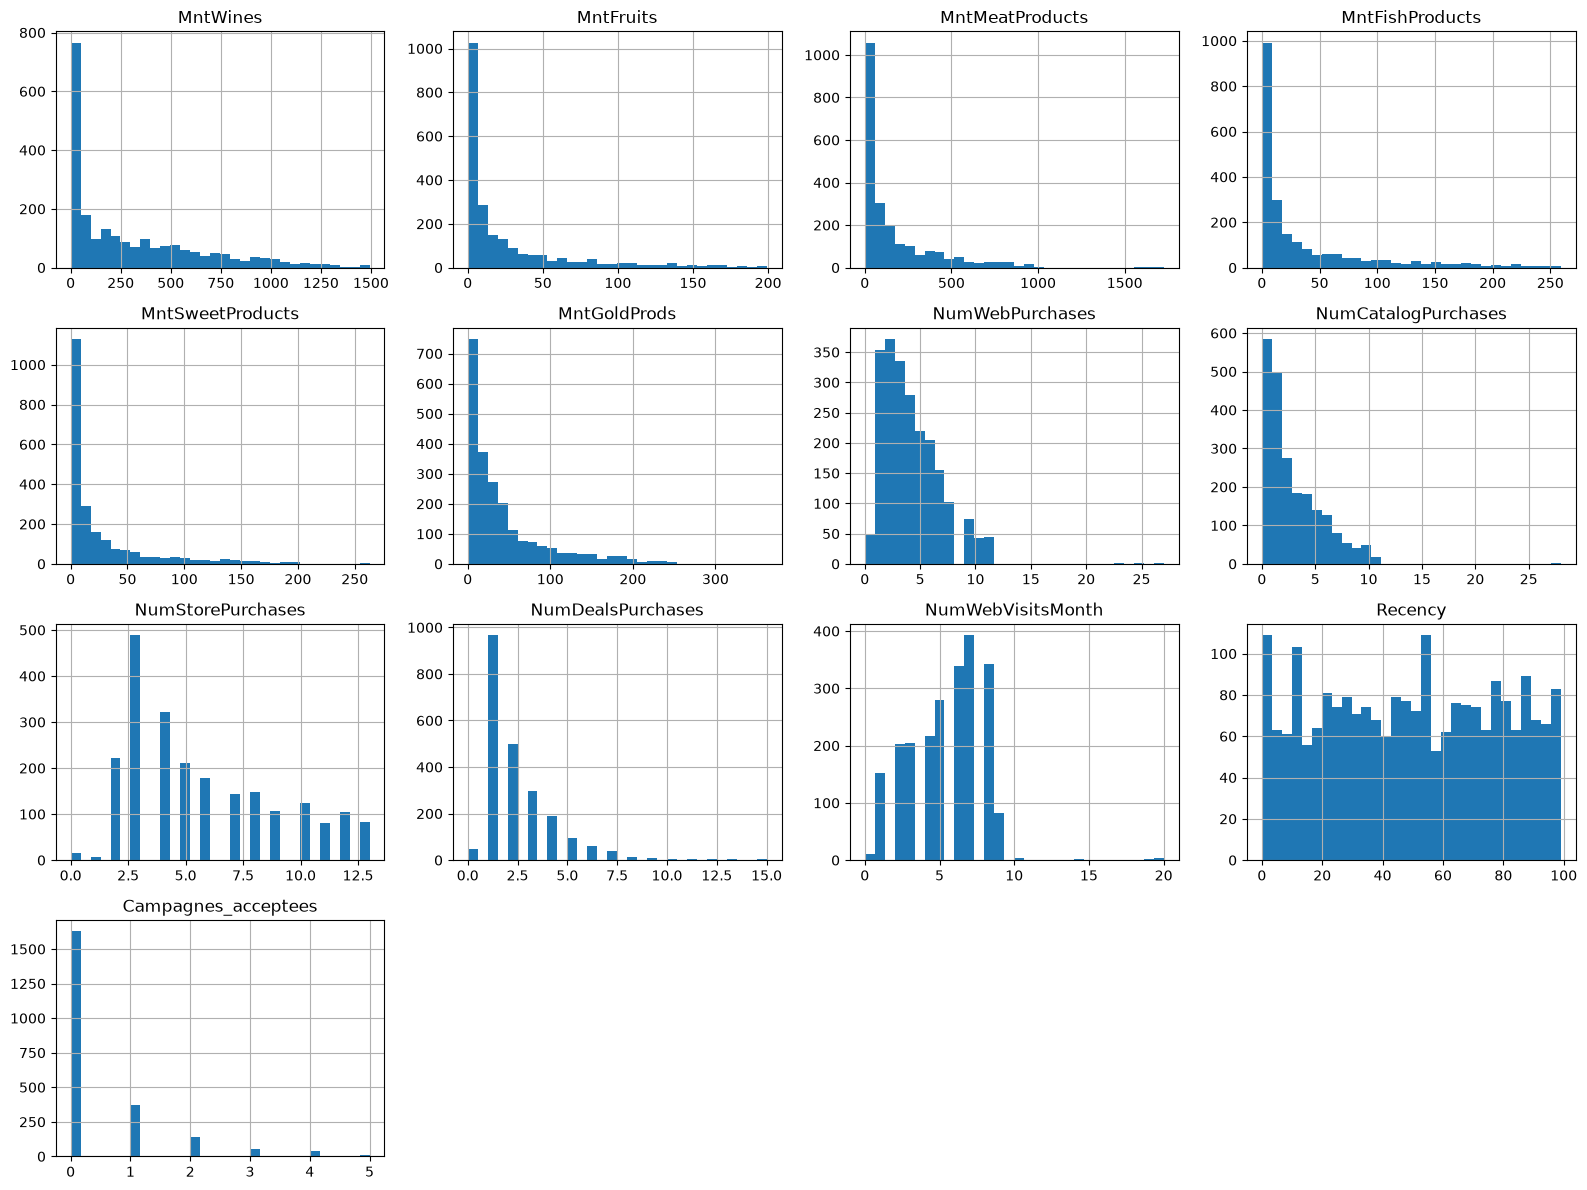

Campagnes_acceptees    2.439585
NumDealsPurchases      2.418461
MntSweetProducts       2.135674
MntFruits              2.104241
MntMeatProducts        2.085282
MntFishProducts        1.919970
MntGoldProds           1.885136
NumCatalogPurchases    1.881437
NumWebPurchases        1.381134
MntWines               1.176036
NumStorePurchases      0.700138
NumWebVisitsMonth      0.207904
Recency               -0.004299
dtype: float64


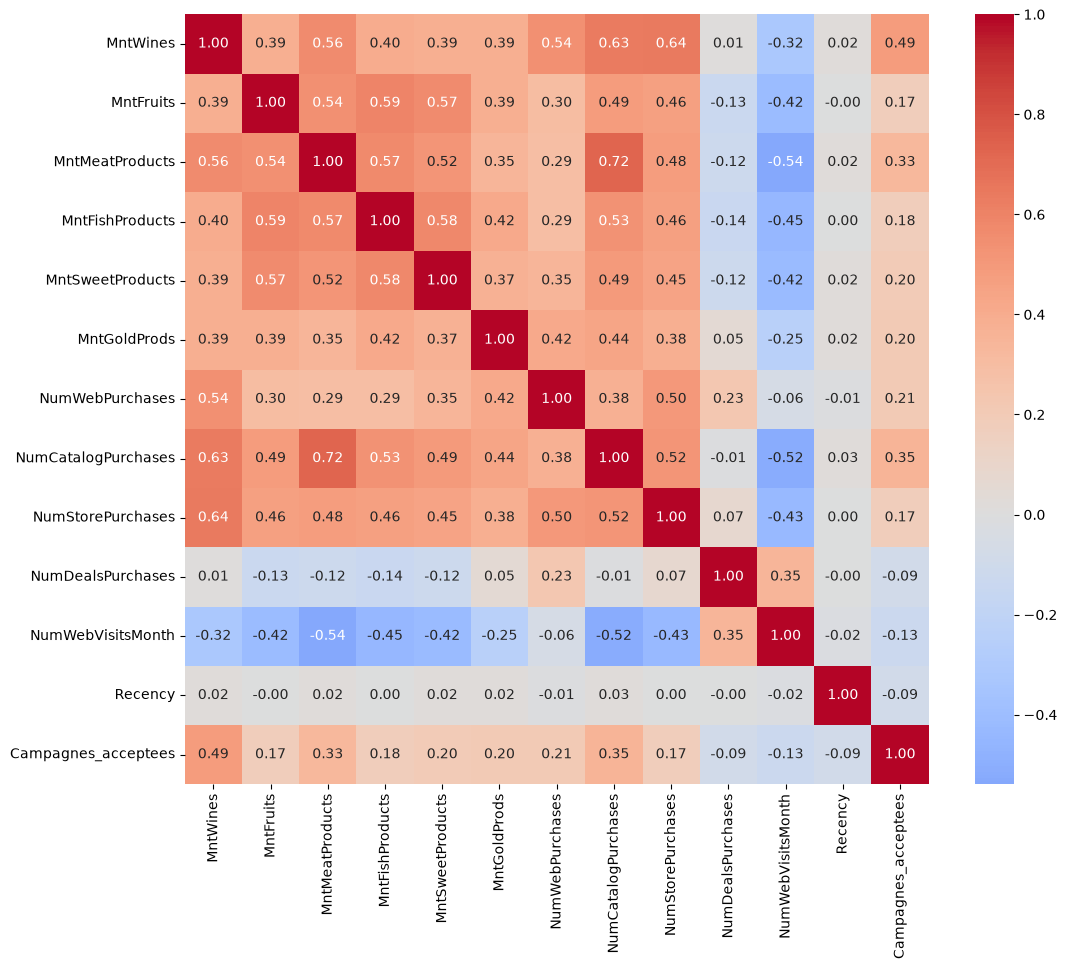

In [113]:
features_clustering = [
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds",
    "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
    "NumDealsPurchases", "NumWebVisitsMonth",
    "Recency", "Campagnes_acceptees",
]
X = df[features_clustering]

# Distributions
X.hist(bins=30, figsize=(16, 12))
plt.tight_layout()
plt.show()

# Asymétrie de chaque variable (skewness)
print(X.skew().sort_values(ascending=False))

# Corrélations
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

### Conclusions
- **Distributions :** les dépenses (`Mnt*`) et plusieurs variables d'achat sont fortement **asymétriques à droite** (skew > 1) : la majorité des clients dépense peu, une minorité dépense beaucoup.
  - Conséquence : KMeans minimise des distances au carré, donc les gros dépensiers domineraient le calcul et la masse des petits clients serait mal différenciée. La standardisation seule ne corrige pas la forme d'une distribution → une transformation logarithmique est nécessaire.
- **Corrélations :**
  - Vin, viande et achats par catalogue/en magasin sont fortement liés : profil probable de clients aisés, acheteurs de produits premium.
  - Fruits, poisson et sucreries sont liés entre eux : panier alimentaire distinct.
  - Les dépenses sont globalement corrélées positivement : un facteur commun de **niveau de dépense** se dégage, que la PCA devrait faire ressortir comme premier axe.
  - `NumWebVisitsMonth` est **négativement corrélée** aux dépenses (environ -0.54 avec `MntMeatProducts` et -0.52 avec `NumCatalogPurchases`) : les clients qui visitent le plus le site sont ceux qui dépensent le moins. Hypothèse : des clients au budget plus serré qui comparent et cherchent les promotions (à confirmer avec la corrélation positive entre `NumWebVisitsMonth` et `NumDealsPurchases`). Pour le marketing : beaucoup de trafic web ne signifie pas beaucoup de chiffre d'affaires.

# V - Transformation et mise à l’échelle

In [116]:
from sklearn.preprocessing import StandardScaler

X = df[features_clustering].copy()

# Variables fortement asymétriques (skew > 1)
skew = X.skew()
cols_log = skew[skew > 1].index.tolist()
print("Variables transformées en log :", cols_log)

# Transformation log1p : log(1 + x)
X[cols_log] = np.log1p(X[cols_log])
print(X.skew().sort_values(ascending=False))

# Standardisation : moyenne 0, écart-type 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features_clustering, index=X.index)
X_scaled.describe().T[["mean", "std"]]

Variables transformées en log : ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumWebPurchases', 'NumCatalogPurchases', 'NumDealsPurchases', 'Campagnes_acceptees']
Campagnes_acceptees    1.555240
NumStorePurchases      0.700138
NumDealsPurchases      0.665689
NumWebVisitsMonth      0.207904
NumCatalogPurchases    0.131493
MntSweetProducts       0.084655
MntFruits              0.083568
Recency               -0.004299
MntFishProducts       -0.052378
MntMeatProducts       -0.084483
NumWebPurchases       -0.265821
MntGoldProds          -0.343379
MntWines              -0.550316
dtype: float64


,mean,std
MntWines,-1.350540e-17,1.000224
MntFruits,-1.112209e-17,1.000224
MntMeatProducts,4.162840e-16,1.000224
MntFishProducts,5.561046e-17,1.000224
MntSweetProducts,4.448836e-17,1.000224
MntGoldProds,1.112209e-16,1.000224
NumWebPurchases,3.352516e-16,1.000224
NumCatalogPurchases,-2.240307e-16,1.000224
NumStorePurchases,-1.322734e-16,1.000224
NumDealsPurchases,1.684202e-16,1.000224


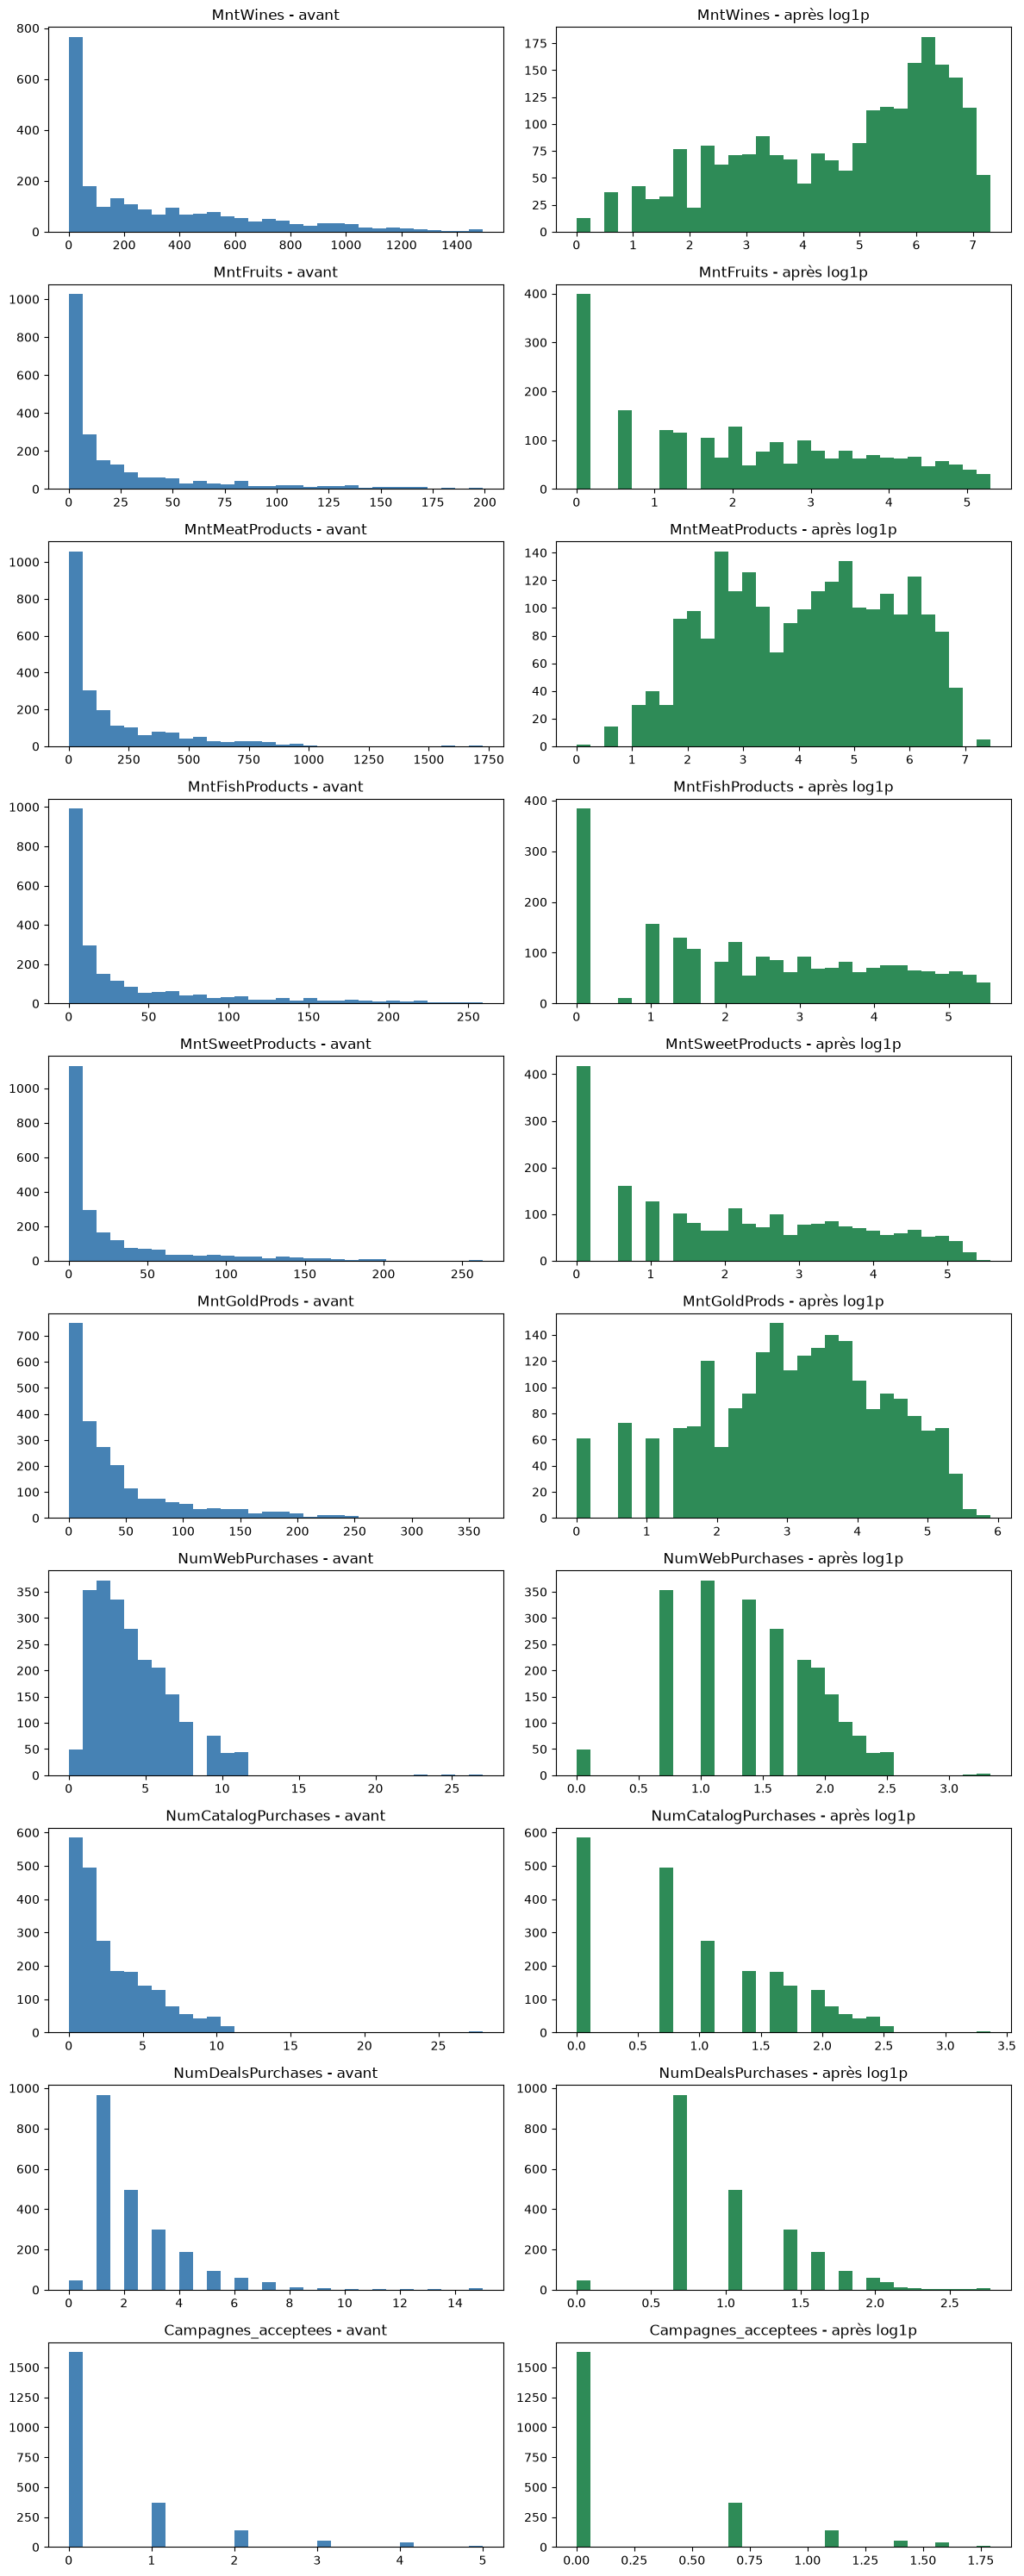

In [118]:
fig, axes = plt.subplots(len(cols_log), 2, figsize=(12, 3 * len(cols_log)))

for i, col in enumerate(cols_log):
    axes[i, 0].hist(df[col], bins=30, color="steelblue")
    axes[i, 0].set_title(f"{col} - avant")
    axes[i, 1].hist(X[col], bins=30, color="seagreen")
    axes[i, 1].set_title(f"{col} - après log1p")

plt.tight_layout()
plt.show()

### Conclusions 
- **Transformation logarithmique** appliquée aux variables fortement asymétriques (skew > 1) : [liste affichée par `cols_log`].
  - On utilise `log1p` (log(1 + x)) car les dépenses contiennent des 0 : `log(0)` donne `-inf`, alors que `log1p(0) = 0`.
  - Après transformation, le skew de ces variables passe de [plage avant] à [plage après] : les distributions sont nettement plus symétriques, les gros dépensiers ne dominent plus les distances.
- Les variables déjà à peu près symétriques (`Recency`, de distribution quasi uniforme, [autres]) ne sont pas transformées : un log y créerait une asymétrie artificielle.
- **Standardisation** (`StandardScaler`) ensuite appliquée à toutes les variables : moyenne 0, écart-type 1, pour qu'aucune ne domine les distances à cause de son unité.
- L'ordre compte : on transforme d'abord la *forme* (log), puis on harmonise l'*échelle* (standardisation).
- Résultat : `X_scaled`, matrice de 2 236 clients × 13 variables, prête pour la PCA et le clustering.

# VI - PCA

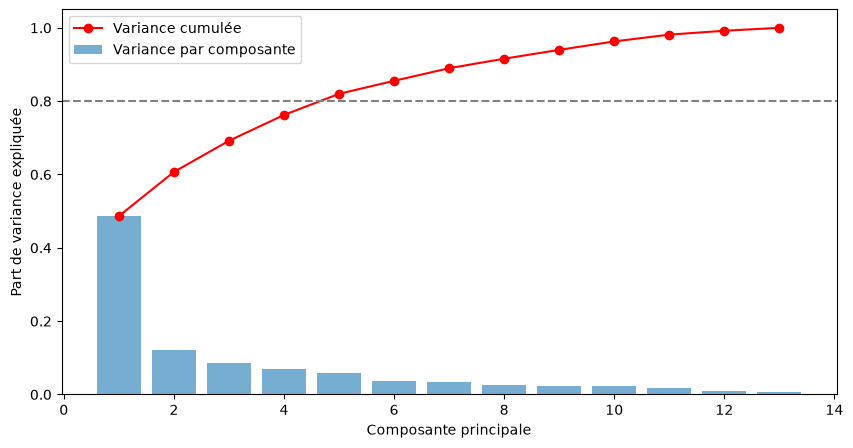

PC1 : 48.7%  (cumulé : 48.7%)
PC2 : 12.0%  (cumulé : 60.7%)
PC3 : 8.5%  (cumulé : 69.2%)
PC4 : 7.0%  (cumulé : 76.2%)
PC5 : 5.8%  (cumulé : 82.0%)
PC6 : 3.6%  (cumulé : 85.5%)
PC7 : 3.4%  (cumulé : 89.0%)
PC8 : 2.6%  (cumulé : 91.6%)
PC9 : 2.4%  (cumulé : 94.0%)
PC10 : 2.3%  (cumulé : 96.3%)
PC11 : 1.8%  (cumulé : 98.1%)
PC12 : 1.1%  (cumulé : 99.2%)
PC13 : 0.8%  (cumulé : 100.0%)


In [119]:
from sklearn.decomposition import PCA

# PCA complète, pour voir combien d'information porte chaque axe
pca = PCA()
pca.fit(X_scaled)

variance = pca.explained_variance_ratio_
variance_cumulee = np.cumsum(variance)

plt.figure(figsize=(10, 5))
plt.bar(range(1, len(variance) + 1), variance, alpha=0.6, label="Variance par composante")
plt.plot(range(1, len(variance) + 1), variance_cumulee, marker="o", color="red", label="Variance cumulée")
plt.axhline(0.8, linestyle="--", color="gray")
plt.xlabel("Composante principale")
plt.ylabel("Part de variance expliquée")
plt.legend()
plt.show()

for i, (v, vc) in enumerate(zip(variance, variance_cumulee), start=1):
    print(f"PC{i} : {v:.1%}  (cumulé : {vc:.1%})")

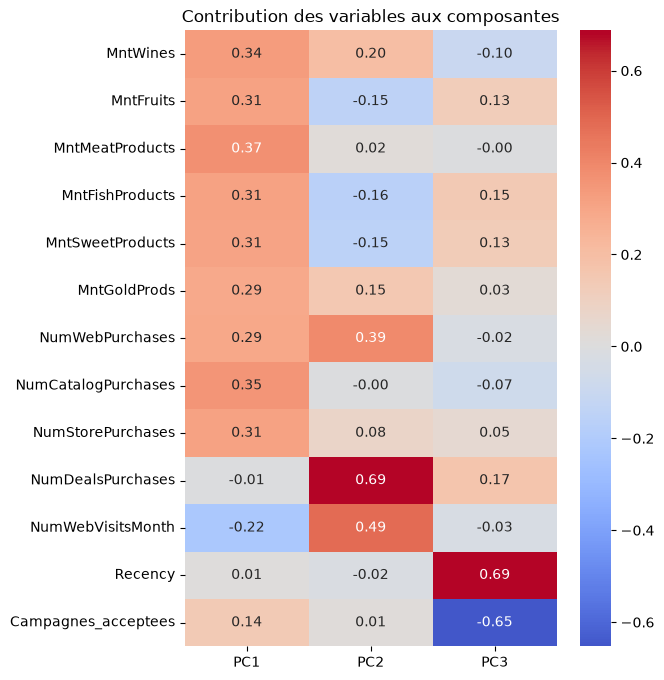

In [120]:
# Contribution de chaque variable aux 3 premières composantes (les "loadings")
loadings = pd.DataFrame(
    pca.components_[:3].T,
    columns=["PC1", "PC2", "PC3"],
    index=features_clustering,
)
plt.figure(figsize=(6, 8))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Contribution des variables aux composantes")
plt.show()

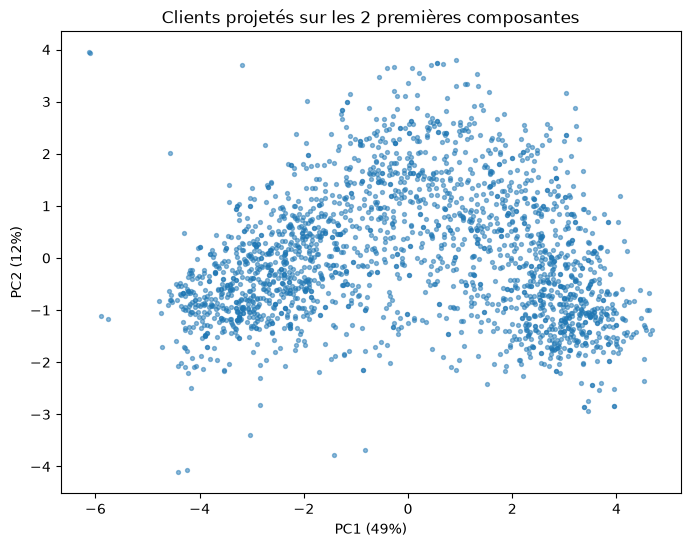

In [121]:
# Projection des clients sur les 2 premiers axes
X_pca = pca.transform(X_scaled)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=8, alpha=0.5)
plt.xlabel(f"PC1 ({variance[0]:.0%})")
plt.ylabel(f"PC2 ({variance[1]:.0%})")
plt.title("Clients projetés sur les 2 premières composantes")
plt.show()

### Conclusions
- **Variance expliquée :** PC1 capte 48,7 % de l'information, PC2 12 %, PC3 8,5 %. Il faut **5 composantes pour atteindre 82 %**. La forte part de PC1 confirme les corrélations de l'analyse exploratoire : un facteur commun domine les données.
- **Interprétation des axes (loadings) :**
  - **PC1 - Niveau d'achat :** toutes les dépenses et tous les achats par canal pèsent positivement (~0,3), les visites web négativement (-0,22). Distingue les gros acheteurs des petits.
  - **PC2 - Chasse aux promotions en ligne :** dominé par `NumDealsPurchases` (0,69), `NumWebVisitsMonth` (0,49) et `NumWebPurchases` (0,39).
  - **PC3 - Désengagement :** `Recency` (+0,69) s'oppose à `Campagnes_acceptees` (-0,65) ; distingue les clients inactifs et peu réceptifs des clients récents et réactifs.
- **Projection PC1 × PC2 :** nuage **continu en forme d'arche**, sans groupes nettement séparés. Les acheteurs moyens sont les plus friands de promotions ; les petits et les gros acheteurs en utilisent peu. Deux zones plus denses apparaissent aux extrémités, et quelques clients atypiques sont isolés.
- **Implication :** la segmentation découpera un continuum plutôt que de révéler des groupes naturellement séparés. KMeans et la CAH devraient fournir des segments exploitables ; DBSCAN risque de peiner. L'interprétation métier sera décisive.

# VII - KMeans

In [122]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pca5 = PCA(n_components=5, random_state=42)
X_pca5 = pca5.fit_transform(X_scaled)
print("Variance conservée :", pca5.explained_variance_ratio_.sum().round(3))

Variance conservée : 0.82


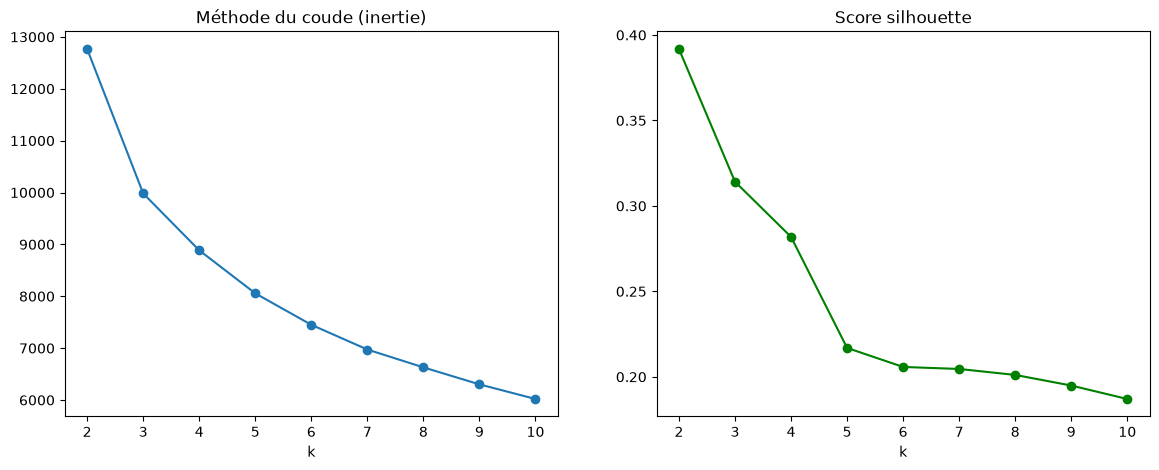

k=2 : silhouette = 0.392
k=3 : silhouette = 0.314
k=4 : silhouette = 0.282
k=5 : silhouette = 0.217
k=6 : silhouette = 0.206
k=7 : silhouette = 0.205
k=8 : silhouette = 0.201
k=9 : silhouette = 0.195
k=10 : silhouette = 0.187


In [123]:
# Tester plusieurs valeurs de k
ks = range(2, 11)
inerties, silhouettes = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_pca5)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca5, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ks, inerties, marker="o")
axes[0].set_title("Méthode du coude (inertie)")
axes[0].set_xlabel("k")
axes[1].plot(ks, silhouettes, marker="o", color="green")
axes[1].set_title("Score silhouette")
axes[1].set_xlabel("k")
plt.show()

for k, s in zip(ks, silhouettes):
    print(f"k={k} : silhouette = {s:.3f}")

Segment_KMeans
0    838
1    309
2    522
3    567
Name: count, dtype: int64


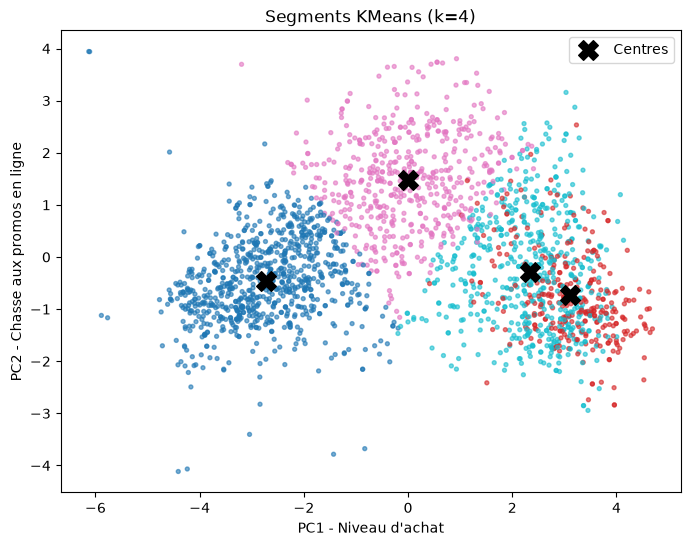

In [128]:
# Entrainer le modèle final avec la valeur de k choisie
K = 4  # à ajuster selon les courbes
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df["Segment_KMeans"] = kmeans.fit_predict(X_pca5)

print(df["Segment_KMeans"].value_counts().sort_index())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca5[:, 0], X_pca5[:, 1], c=df["Segment_KMeans"], cmap="tab10", s=8, alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="black", marker="X", s=200, label="Centres")
plt.xlabel("PC1 - Niveau d'achat")
plt.ylabel("PC2 - Chasse aux promos en ligne")
plt.legend()
plt.title(f"Segments KMeans (k={K})")
plt.show()

# Projection sur PC1 × PC3
plt.figure(figsize=(8, 6))
plt.scatter(X_pca5[:, 0], X_pca5[:, 2], c=df["Segment_KMeans"], cmap="tab10", s=8, alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 2],
            c="black", marker="X", s=200)
plt.xlabel("PC1 - Niveau d'achat")
plt.ylabel("PC3 - Désengagement")
plt.title("Segments KMeans sur PC1 × PC3")
plt.show()

# Moyennes des variables clés par segment, dans leurs unités d'origine
df.groupby("Segment_KMeans")[[
    "Depenses_totales", "NumDealsPurchases", "NumWebVisitsMonth",
    "Recency", "Campagnes_acceptees"
]].mean().round(1)

### Conclusions
- **Données utilisées :** les 5 premières composantes PCA (82 % de la variance), pour éliminer la redondance entre variables de dépense et réduire le bruit.
- **Choix de k = 4 :**
  - le coude de l'inertie se situe autour de 3-4 ;
  - le score silhouette passe de 0,39 (k=2) à 0,28 (k=4), puis **chute à 0,22 à k=5** ;
  - k=2 a le meilleur score mais se réduit à « petits vs gros acheteurs », sans valeur ajoutée pour le marketing. k=4 est le meilleur compromis entre qualité géométrique et actionnabilité.
- **Taille des segments :** équilibrée, de 14 % à 37 % des clients ; aucun segment marginal.
- **Lecture des projections :**
  - sur PC1 × PC2, KMeans découpe l'arche : petits acheteurs à gauche, chasseurs de promos au sommet, gros acheteurs à droite ;
  - deux segments de gros acheteurs se chevauchent sur PC1 × PC2 mais **se séparent sur PC3** : une projection 2D ne montre qu'une partie de la structure.
- **Segments obtenus :**
  - **Segment 0 - Petits acheteurs (37 %)** : ~70 de dépenses, beaucoup de visites web, insensibles aux campagnes.
  - **Segment 2 - Chasseurs de promos (23 %)** : ~500 de dépenses, 4,1 achats en promotion, 6,8 visites web/mois.
  - **Segment 3 - Gros acheteurs autonomes (25 %)** : ~1 000 de dépenses, aucune campagne acceptée.
  - **Segment 1 - Premium engagés (14 %)** : ~1 500 de dépenses, 2 campagnes acceptées en moyenne.
- **Observations clés :**
  - `Recency` est quasi identique dans tous les segments (47 à 51 jours) : elle ne contribue pas à la segmentation.
  - Les campagnes actuelles ne touchent réellement que le segment premium ; le segment 3, à forte valeur, y est totalement imperméable.

# VIII - La CAH

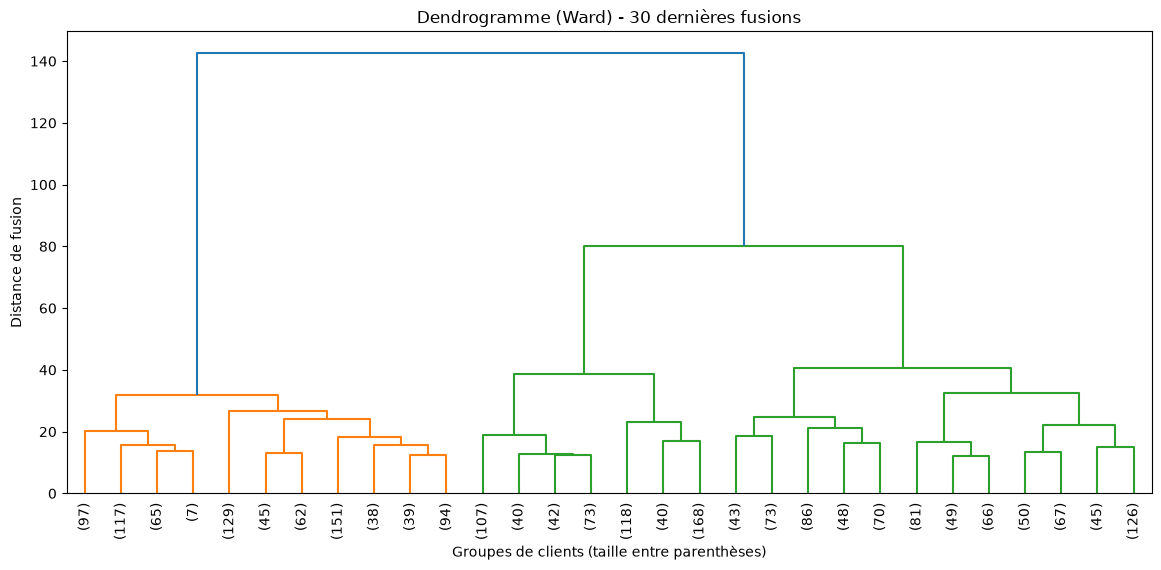

In [132]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# Arbre de fusion avec la méthode de Ward
Z = linkage(X_pca5, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogramme (Ward) - 30 dernières fusions")
plt.xlabel("Groupes de clients (taille entre parenthèses)")
plt.ylabel("Distance de fusion")
plt.show()

In [133]:
# Modèle CAH avec 4 segments, pour comparer avec KMeans
cah = AgglomerativeClustering(n_clusters=4, linkage="ward")
df["Segment_CAH"] = cah.fit_predict(X_pca5)

print(df["Segment_CAH"].value_counts().sort_index())
print("Silhouette CAH :", round(silhouette_score(X_pca5, df["Segment_CAH"]), 3))

# Correspondance entre les deux segmentations
pd.crosstab(df["Segment_KMeans"], df["Segment_CAH"])

Segment_CAH
0    588
1    844
2    484
3    320
Name: count, dtype: int64
Silhouette CAH : 0.247


Segment_CAH,0,1,2,3
Segment_KMeans,,,,
0,0,807,22,9
1,278,0,7,24
2,0,33,206,283
3,310,4,249,4


# ### Conclusions
- **Dendrogramme (Ward) :**
  - la plus grande séparation (distance 80 → 143) donne **2 segments**, cohérent avec le silhouette maximal de KMeans à k=2 ;
  - une seconde séparation nette (40 → 80) donne **3 segments** ;
  - **4 segments ne sont pas naturels pour la CAH** : la coupe se fait dans une bande très étroite (38,7 à 40,5).
- **CAH à 4 segments :** tailles de 320 à 844 clients, silhouette de **0,247** (contre 0,28 pour KMeans k=4).
- **Comparaison avec KMeans (crosstab) :**
  - **Accord fort sur les petits acheteurs** : 96 % du segment KMeans 0 se retrouvent dans un même segment CAH. C'est le segment le plus robuste.
  - La CAH **fusionne les deux segments de gros acheteurs** de KMeans (premium engagés et gros acheteurs autonomes) : elle ne les distingue pas selon leur réceptivité aux campagnes.
  - Les frontières dans la zone intermédiaire (chasseurs de promos) diffèrent entre les deux méthodes.
- **Interprétation :** les méthodes s'accordent là où la structure est forte et divergent dans les zones de continuum. Les fusions de la CAH étant irréversibles, une fusion précoce sous-optimale se répercute sur le résultat final.
- **Décision :** on conserve **KMeans k=4**, qui a un meilleur silhouette et isole le segment premium réceptif aux campagnes, le plus utile pour le marketing. La CAH valide la robustesse du segment des petits acheteurs.

# DBSCAN

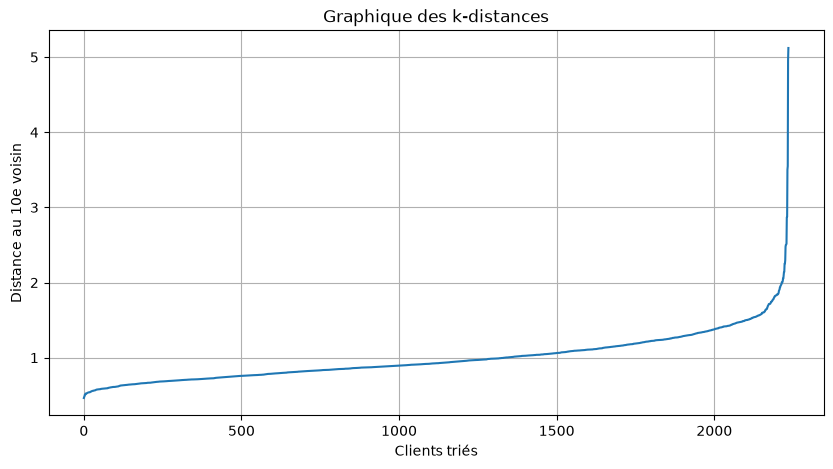

In [134]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

min_samples = 10

# Distance de chaque client à son 10e plus proche voisin, triée
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_pca5)
distances, _ = nn.kneighbors(X_pca5)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_dist)
plt.xlabel("Clients triés")
plt.ylabel(f"Distance au {min_samples}e voisin")
plt.title("Graphique des k-distances")
plt.grid(True)
plt.show()